SMART CITY FINAL DASHBOARD 

In [2]:
# Import required libraries

import pandas as pd
import numpy as np
import mysql.connector
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

In [3]:
# Load Crime Dataset

crime_df = pd.read_csv(
    "crime.csv"
)

# Load Electricity Dataset

electricity_df = pd.read_csv(
    "energy.csv"
)

# Load Smart Mobility Dataset

mobility_df = pd.read_csv(
    "traffic.csv"
)

# Load Waste Management Dataset

waste_df = pd.read_csv(
    "waste.csv"
)

print("Crime Shape:", crime_df.shape)
print("Electricity Shape:", electricity_df.shape)
print("Mobility Shape:", mobility_df.shape)
print("Waste Shape:", waste_df.shape)


Crime Shape: (40160, 14)
Electricity Shape: (47, 8)
Mobility Shape: (5000, 15)
Waste Shape: (25203, 42)


In [5]:
# Remove unnecessary spaces from column names

crime_df.columns = crime_df.columns.str.strip()
electricity_df.columns = electricity_df.columns.str.strip()
mobility_df.columns = mobility_df.columns.str.strip()
waste_df.columns = waste_df.columns.str.strip()

# Clean city names

crime_df["City"] = crime_df["City"].astype(str).str.strip().str.title()

electricity_df["City"] = (
    electricity_df["City"]
    .astype(str)
    .str.strip()
)

waste_df["City"] = (
    waste_df["City"]
    .astype(str)
    .str.strip()
    .str.title()
)

print("Column cleaning completed")



Column cleaning completed


In [7]:
# Connect to MySQL server

connection = mysql.connector.connect(
    host="localhost",
    user="root",
    password="Saxena@123"
)

cursor = connection.cursor()

print("Connected to MySQL successfully")


Connected to MySQL successfully


In [8]:
# Create Smart City database

cursor.execute(
    "CREATE DATABASE IF NOT EXISTS smart_city_data"
)

cursor.execute(
    "USE smart_city_data"
)

connection.commit()

print("Database smart_city_data is ready")


Database smart_city_data is ready


In [9]:
# Create crime_data table

cursor.execute("""
CREATE TABLE IF NOT EXISTS crime_data (
    report_number INT,
    date_reported DATETIME NULL,
    date_of_occurrence DATETIME NULL,
    time_of_occurrence DATETIME NULL,
    city VARCHAR(100),
    crime_code INT,
    crime_description VARCHAR(255),
    victim_age INT,
    victim_gender VARCHAR(20),
    weapon_used VARCHAR(100),
    crime_domain VARCHAR(100),
    police_deployed INT,
    case_closed VARCHAR(20),
    date_case_closed DATETIME NULL
)
""")

connection.commit()

print("crime_data table created")



crime_data table created


In [10]:
# Create electricity_data table

cursor.execute("""
CREATE TABLE IF NOT EXISTS electricity_data (
    city VARCHAR(150),
    year VARCHAR(20),
    domestic_consumption DECIMAL(15,2),
    commercial_consumption DECIMAL(15,2),
    industry_consumption DECIMAL(15,2),
    public_water_street_consumption DECIMAL(15,2),
    other_consumption DECIMAL(15,2),
    total_consumption DECIMAL(15,2)
)
""")

connection.commit()

print("electricity_data table created")


electricity_data table created


In [11]:
# Create smart_mobility_data table

cursor.execute("""
CREATE TABLE IF NOT EXISTS smart_mobility_data (
    timestamp DATETIME,
    latitude DOUBLE,
    longitude DOUBLE,
    vehicle_count INT,
    traffic_speed_kmh DOUBLE,
    road_occupancy_percent DOUBLE,
    traffic_light_state VARCHAR(30),
    weather_condition VARCHAR(50),
    accident_report INT,
    sentiment_score DOUBLE,
    ride_sharing_demand INT,
    parking_availability INT,
    emission_levels_g_km DOUBLE,
    energy_consumption_l_h DOUBLE,
    traffic_condition VARCHAR(30)
)
""")

connection.commit()

print("smart_mobility_data table created")


smart_mobility_data table created


In [12]:
# Create waste_management_data table

cursor.execute("""
CREATE TABLE IF NOT EXISTS waste_management_data (
    record_id VARCHAR(50),
    city VARCHAR(100),
    state VARCHAR(100),
    region VARCHAR(100),
    city_category VARCHAR(50),
    year INT,
    month INT,
    season VARCHAR(30),
    population BIGINT,
    population_density DOUBLE,
    urbanization_rate DOUBLE,
    waste_type VARCHAR(50),
    daily_waste_generation_tons DOUBLE,
    waste_per_capita_kg DOUBLE,
    collection_efficiency_percentage DOUBLE,
    waste_segregation_rate DOUBLE,
    recycling_rate DOUBLE,
    composting_rate DOUBLE,
    landfill_dependency_rate DOUBLE,
    waste_processing_capacity DOUBLE,
    treatment_method VARCHAR(100),
    municipal_efficiency_score DOUBLE,
    awareness_campaigns_count INT,
    smart_bins_count INT,
    waste_collection_vehicles INT,
    garbage_collection_frequency INT,
    worker_count INT,
    waste_management_budget_inr DOUBLE,
    cost_per_ton_inr DOUBLE,
    carbon_emission_from_waste DOUBLE,
    landfill_capacity_tons DOUBLE,
    landfill_remaining_capacity DOUBLE,
    latitude DOUBLE,
    longitude DOUBLE,
    air_quality_index DOUBLE,
    rainfall_mm DOUBLE,
    tourism_impact_score DOUBLE,
    industrial_activity_level DOUBLE,
    population_growth_rate DOUBLE,
    sustainability_index DOUBLE,
    waste_management_performance_level VARCHAR(50),
    sustainability_category VARCHAR(50)
)
""")

connection.commit()

print("waste_management_data table created")


waste_management_data table created


In [14]:
# Convert date columns into MySQL-compatible datetime values

crime_df["Date Reported"] = pd.to_datetime(
    crime_df["Date Reported"],
    errors="coerce"
)

crime_df["Date of Occurrence"] = pd.to_datetime(
    crime_df["Date of Occurrence"],
    errors="coerce"
)

crime_df["Time of Occurrence"] = pd.to_datetime(
    crime_df["Time of Occurrence"],
    errors="coerce"
)

crime_df["Date Case Closed"] = pd.to_datetime(
    crime_df["Date Case Closed"],
    errors="coerce"
)

# Replace NaN with None

crime_df = crime_df.where(
    pd.notnull(crime_df),
    None
)

print(crime_df.head())


   Report Number       Date Reported  Date of Occurrence  Time of Occurrence  \
0              1 2020-02-01 00:00:00 2020-01-01 00:00:00 2020-01-01 01:11:00   
1              2 2020-01-01 19:00:00 2020-01-01 01:00:00 2020-01-01 06:26:00   
2              3 2020-02-01 05:00:00 2020-01-01 02:00:00 2020-01-01 14:30:00   
3              4 2020-01-01 05:00:00 2020-01-01 03:00:00 2020-01-01 14:46:00   
4              5 2020-01-01 21:00:00 2020-01-01 04:00:00 2020-01-01 16:51:00   

        City  Crime Code Crime Description  Victim Age Victim Gender  \
0  Ahmedabad         576    IDENTITY THEFT          16             M   
1    Chennai         128          HOMICIDE          37             M   
2   Ludhiana         271        KIDNAPPING          48             F   
3       Pune         170          BURGLARY          49             F   
4       Pune         421         VANDALISM          30             F   

    Weapon Used   Crime Domain  Police Deployed Case Closed  \
0  Blunt Object  Violen

In [19]:
# ==========================================
# INSERT CRIME DATA INTO MYSQL - FIXED
# ==========================================


import pandas as pd
import datetime
import numpy as np

# ------------------------------------------
# STEP 1: Convert date/time columns
# ------------------------------------------

crime_df["Date Reported"] = pd.to_datetime(
    crime_df["Date Reported"],
    errors="coerce"
)

crime_df["Date of Occurrence"] = pd.to_datetime(
    crime_df["Date of Occurrence"],
    errors="coerce"
)

crime_df["Time of Occurrence"] = pd.to_datetime(
    crime_df["Time of Occurrence"],
    errors="coerce"
)

crime_df["Date Case Closed"] = pd.to_datetime(
    crime_df["Date Case Closed"],
    errors="coerce"
)


# ------------------------------------------
# STEP 2: Convert Pandas values to
#         MySQL-compatible Python values
# ------------------------------------------

def mysql_value(value):

    # Missing value
    if pd.isna(value):
        return None

    # Pandas Timestamp -> Python datetime
    if isinstance(value, pd.Timestamp):
        return value.to_pydatetime()

    # NumPy integer -> Python int
    if isinstance(value, np.integer):
        return int(value)

    # NumPy float -> Python float
    if isinstance(value, np.floating):
        return float(value)

    # NumPy boolean -> Python bool
    if isinstance(value, np.bool_):
        return bool(value)

    # Everything else
    return value


# ------------------------------------------
# STEP 3: Columns used in MySQL
# ------------------------------------------

crime_columns = [
    "Report Number",
    "Date Reported",
    "Date of Occurrence",
    "Time of Occurrence",
    "City",
    "Crime Code",
    "Crime Description",
    "Victim Age",
    "Victim Gender",
    "Weapon Used",
    "Crime Domain",
    "Police Deployed",
    "Case Closed",
    "Date Case Closed"
]


# ------------------------------------------
# STEP 4: Create MySQL-compatible records
# ------------------------------------------

crime_records = []

for row in crime_df[crime_columns].itertuples(
    index=False,
    name=None
):

    converted_row = tuple(
        mysql_value(value)
        for value in row
    )

    crime_records.append(converted_row)


# ------------------------------------------
# STEP 5: MySQL INSERT query
# ------------------------------------------

crime_sql = """
INSERT INTO crime_data
(
    report_number,
    date_reported,
    date_of_occurrence,
    time_of_occurrence,
    city,
    crime_code,
    crime_description,
    victim_age,
    victim_gender,
    weapon_used,
    crime_domain,
    police_deployed,
    case_closed,
    date_case_closed
)
VALUES
(
    %s, %s, %s, %s, %s, %s, %s,
    %s, %s, %s, %s, %s, %s, %s
)
"""


# ------------------------------------------
# STEP 6: Insert into MySQL
# ------------------------------------------

try:

    cursor.executemany(
        crime_sql,
        crime_records
    )

    connection.commit()

    print(
        f"{len(crime_records)} crime records inserted successfully."
    )

except Exception as e:

    connection.rollback()

    print("ERROR WHILE INSERTING CRIME DATA:")
    print(type(e).__name__)
    print(e)



40160 crime records inserted successfully.


In [21]:
# Rename electricity columns

electricity_df = electricity_df.rename(columns={
    "Consumption of Electricity (in lakh units)-Domestic purpose":
        "domestic_consumption",

    "Consumption of Electricity (in lakh units)-Commercial purpose":
        "commercial_consumption",

    "Consumption of Electricity (in lakh units)-Industry purpose":
        "industry_consumption",

    "Consumption of Electricity (in lakh units)-Public Water Work & Street Light":
        "public_water_street_consumption",

    "Consumption of Electricity (in lakh units)-Others":
        "other_consumption",

    "Consumption of Electricity (in lakh units)-Total Consumption":
        "total_consumption"
})

# Normalize city names

electricity_df["city_normalized"] = (
    electricity_df["City"]
    .str.strip()
    .str.lower()
)

city_mapping = {
    "bengaluru": "Bangalore",
    "jaipur-c-i": "Jaipur",
    "jaipur-c-ii": "Jaipur",
    "jaipur-c-iii": "Jaipur",
    "jaipur-c-iv": "Jaipur",
    "kanpur nagar": "Kanpur",
    "new town kolkata": "Kolkata",
    "srinagar": "Srinagar",
    "kota": "Kota",
    "ndmc": "Delhi"
}

electricity_df["City"] = (
    electricity_df["city_normalized"]
    .map(city_mapping)
    .fillna(electricity_df["City"].str.strip().str.title())
)

electricity_df = electricity_df.drop(
    columns=["city_normalized"]
)

electricity_df = electricity_df.where(
    pd.notnull(electricity_df),
    None
)

display(electricity_df.head())


,City,Year,domestic_consumption,commercial_consumption,industry_consumption,public_water_street_consumption,other_consumption,total_consumption
0,Agartala,2018-19,213.98,30.80,5.94,13.13,55.25,319.10
1,Agra,2017-18,9772.00,3811.00,2870.00,583.00,157.00,17191.00
2,Aizawl,2018-19,2386.93,481.15,133.41,437.78,518.55,3957.82
3,Amritsar,2017-18,4076.09,2131.73,1479.03,206.00,166.24,8059.09
4,Aurangabad Maharashtra (Total Consumption/Month),2017-18,275.07,83.97,121.08,18.38,19.12,517.62


In [23]:
# Insert electricity records

electricity_sql = """
INSERT INTO electricity_data (
    city,
    year,
    domestic_consumption,
    commercial_consumption,
    industry_consumption,
    public_water_street_consumption,
    other_consumption,
    total_consumption
)
VALUES (%s,%s,%s,%s,%s,%s,%s,%s)
"""

electricity_records = list(
    electricity_df[
        [
            "City",
            "Year",
            "domestic_consumption",
            "commercial_consumption",
            "industry_consumption",
            "public_water_street_consumption",
            "other_consumption",
            "total_consumption"
        ]
    ].itertuples(index=False, name=None)
)

cursor.executemany(
    electricity_sql,
    electricity_records
)

connection.commit()

print(len(electricity_records), "electricity records inserted")


47 electricity records inserted


In [25]:
# Convert timestamp

mobility_df["Timestamp"] = pd.to_datetime(
    mobility_df["Timestamp"],
    errors="coerce"
)

# Replace NaN with None

mobility_df = mobility_df.where(
    pd.notnull(mobility_df),
    None
)

display(mobility_df.head())


,Timestamp,Latitude,Longitude,Vehicle_Count,Traffic_Speed_kmh,Road_Occupancy_%,Traffic_Light_State,Weather_Condition,Accident_Report,Sentiment_Score,Ride_Sharing_Demand,Parking_Availability,Emission_Levels_g_km,Energy_Consumption_L_h,Traffic_Condition
0,2024-03-01 00:00:00,40.842275,-73.703149,205,49.893435,82.652780,Yellow,Clear,0,-0.609199,2,45,450.760055,19.574337,High
1,2024-03-01 00:05:00,40.831119,-73.987354,202,22.383965,45.829298,Green,Clear,0,0.965442,16,1,321.800341,5.385554,High
2,2024-03-01 00:10:00,40.819549,-73.732462,252,46.889699,82.772465,Green,Rain,0,0.289660,16,49,231.152655,10.277477,High
3,2024-03-01 00:15:00,40.725849,-73.980134,37,5.730536,37.695567,Red,Fog,0,-0.271965,66,10,410.384292,29.243279,High
4,2024-03-01 00:20:00,40.813265,-73.961631,64,61.348034,22.313358,Red,Snow,0,-0.797606,3,5,364.466342,16.801459,Low


In [29]:
# ==========================================
# CELL 16 - INSERT SMART MOBILITY DATA
# ==========================================

print("By Sanskriti Saxena")

import pandas as pd
import numpy as np
import datetime


# ------------------------------------------
# STEP 1: SHOW ACTUAL COLUMN NAMES
# ------------------------------------------

print("Columns present in mobility_df:")

for i, col in enumerate(mobility_df.columns):
    print(i, ":", repr(col))


# ------------------------------------------
# STEP 2: Clean column names
# ------------------------------------------

mobility_df.columns = (
    mobility_df.columns
    .str.strip()
    .str.replace("\n", " ", regex=False)
)


print("\nCleaned columns:")

for col in mobility_df.columns:
    print(repr(col))


# ------------------------------------------
# STEP 3: Convert Timestamp
# ------------------------------------------

# Find timestamp column automatically

timestamp_column = None

for col in mobility_df.columns:
    if col.lower().strip() in [
        "timestamp",
        "time stamp",
        "date",
        "datetime",
        "date time"
    ]:
        timestamp_column = col
        break


if timestamp_column is None:

    print("\nTimestamp column was not found.")

else:

    print("\nTimestamp column found:", timestamp_column)

    mobility_df[timestamp_column] = pd.to_datetime(
        mobility_df[timestamp_column],
        errors="coerce"
    )


# ------------------------------------------
# STEP 4: Convert values to MySQL types
# ------------------------------------------

def convert_mysql_value(value):

    if pd.isna(value):
        return None

    if isinstance(value, pd.Timestamp):
        return value.to_pydatetime()

    if isinstance(value, np.integer):
        return int(value)

    if isinstance(value, np.floating):
        return float(value)

    if isinstance(value, np.bool_):
        return bool(value)

    return value


# ------------------------------------------
# STEP 5: USE ACTUAL DATASET COLUMNS
# ------------------------------------------

print("\nDataset shape:")
print(mobility_df.shape)

print("\nFirst 5 rows:")
display(mobility_df.head())


# ------------------------------------------
# STEP 6: Prepare records
# ------------------------------------------

mobility_records = []

for row in mobility_df.itertuples(
    index=False,
    name=None
):

    converted_row = tuple(
        convert_mysql_value(value)
        for value in row
    )

    mobility_records.append(converted_row)


print(
    "\nTotal mobility records:",
    len(mobility_records)
)


# ------------------------------------------
# STEP 7: SHOW COLUMN COUNT
# ------------------------------------------

print(
    "Number of DataFrame columns:",
    len(mobility_df.columns)
)


# ------------------------------------------
# STEP 8: IMPORTANT
# ------------------------------------------

print("\nActual columns that will be inserted:")

for col in mobility_df.columns:
    print("-", col)


print("\nDo NOT run the MySQL INSERT yet.")


By Sanskriti Saxena
Columns present in mobility_df:
0 : 'Timestamp'
1 : 'Latitude'
2 : 'Longitude'
3 : 'Vehicle_Count'
4 : 'Traffic_Speed_kmh'
5 : 'Road_Occupancy_%'
6 : 'Traffic_Light_State'
7 : 'Weather_Condition'
8 : 'Accident_Report'
9 : 'Sentiment_Score'
10 : 'Ride_Sharing_Demand'
11 : 'Parking_Availability'
12 : 'Emission_Levels_g_km'
13 : 'Energy_Consumption_L_h'
14 : 'Traffic_Condition'

Cleaned columns:
'Timestamp'
'Latitude'
'Longitude'
'Vehicle_Count'
'Traffic_Speed_kmh'
'Road_Occupancy_%'
'Traffic_Light_State'
'Weather_Condition'
'Accident_Report'
'Sentiment_Score'
'Ride_Sharing_Demand'
'Parking_Availability'
'Emission_Levels_g_km'
'Energy_Consumption_L_h'
'Traffic_Condition'

Timestamp column found: Timestamp

Dataset shape:
(5000, 15)

First 5 rows:


,Timestamp,Latitude,Longitude,Vehicle_Count,Traffic_Speed_kmh,Road_Occupancy_%,Traffic_Light_State,Weather_Condition,Accident_Report,Sentiment_Score,Ride_Sharing_Demand,Parking_Availability,Emission_Levels_g_km,Energy_Consumption_L_h,Traffic_Condition
0,2024-03-01 00:00:00,40.842275,-73.703149,205,49.893435,82.652780,Yellow,Clear,0,-0.609199,2,45,450.760055,19.574337,High
1,2024-03-01 00:05:00,40.831119,-73.987354,202,22.383965,45.829298,Green,Clear,0,0.965442,16,1,321.800341,5.385554,High
2,2024-03-01 00:10:00,40.819549,-73.732462,252,46.889699,82.772465,Green,Rain,0,0.289660,16,49,231.152655,10.277477,High
3,2024-03-01 00:15:00,40.725849,-73.980134,37,5.730536,37.695567,Red,Fog,0,-0.271965,66,10,410.384292,29.243279,High
4,2024-03-01 00:20:00,40.813265,-73.961631,64,61.348034,22.313358,Red,Snow,0,-0.797606,3,5,364.466342,16.801459,Low



Total mobility records: 5000
Number of DataFrame columns: 15

Actual columns that will be inserted:
- Timestamp
- Latitude
- Longitude
- Vehicle_Count
- Traffic_Speed_kmh
- Road_Occupancy_%
- Traffic_Light_State
- Weather_Condition
- Accident_Report
- Sentiment_Score
- Ride_Sharing_Demand
- Parking_Availability
- Emission_Levels_g_km
- Energy_Consumption_L_h
- Traffic_Condition

Do NOT run the MySQL INSERT yet.


In [31]:
# Replace NaN with None

waste_df = waste_df.where(
    pd.notnull(waste_df),
    None
)

waste_sql = """
INSERT INTO waste_management_data (
    record_id,
    city,
    state,
    region,
    city_category,
    year,
    month,
    season,
    population,
    population_density,
    urbanization_rate,
    waste_type,
    daily_waste_generation_tons,
    waste_per_capita_kg,
    collection_efficiency_percentage,
    waste_segregation_rate,
    recycling_rate,
    composting_rate,
    landfill_dependency_rate,
    waste_processing_capacity,
    treatment_method,
    municipal_efficiency_score,
    awareness_campaigns_count,
    smart_bins_count,
    waste_collection_vehicles,
    garbage_collection_frequency,
    worker_count,
    waste_management_budget_inr,
    cost_per_ton_inr,
    carbon_emission_from_waste,
    landfill_capacity_tons,
    landfill_remaining_capacity,
    latitude,
    longitude,
    air_quality_index,
    rainfall_mm,
    tourism_impact_score,
    industrial_activity_level,
    population_growth_rate,
    sustainability_index,
    waste_management_performance_level,
    sustainability_category
)
VALUES (
    %s,%s,%s,%s,%s,%s,%s,%s,%s,%s,
    %s,%s,%s,%s,%s,%s,%s,%s,%s,%s,
    %s,%s,%s,%s,%s,%s,%s,%s,%s,%s,
    %s,%s,%s,%s,%s,%s,%s,%s,%s,%s,
    %s,%s
)
"""

waste_columns = [
    "Record_ID",
    "City",
    "State",
    "Region",
    "City_Category",
    "Year",
    "Month",
    "Season",
    "Population",
    "Population_Density",
    "Urbanization_Rate",
    "Waste_Type",
    "Daily_Waste_Generation_Tons",
    "Waste_Per_Capita_KG",
    "Collection_Efficiency_Percentage",
    "Waste_Segregation_Rate",
    "Recycling_Rate",
    "Composting_Rate",
    "Landfill_Dependency_Rate",
    "Waste_Processing_Capacity",
    "Treatment_Method",
    "Municipal_Efficiency_Score",
    "Awareness_Campaigns_Count",
    "Smart_Bins_Count",
    "Waste_Collection_Vehicles",
    "Garbage_Collection_Frequency",
    "Worker_Count",
    "Waste_Management_Budget_INR",
    "Cost_Per_Ton_INR",
    "Carbon_Emission_From_Waste",
    "Landfill_Capacity_Tons",
    "Landfill_Remaining_Capacity",
    "Latitude",
    "Longitude",
    "Air_Quality_Index",
    "Rainfall_MM",
    "Tourism_Impact_Score",
    "Industrial_Activity_Level",
    "Population_Growth_Rate",
    "Sustainability_Index",
    "Waste_Management_Performance_Level",
    "Sustainability_Category"
]

waste_records = list(
    waste_df[waste_columns]
    .itertuples(index=False, name=None)
)

# Insert in chunks

chunk_size = 1000

for i in range(0, len(waste_records), chunk_size):

    chunk = waste_records[
        i:i + chunk_size
    ]

    cursor.executemany(
        waste_sql,
        chunk
    )

    connection.commit()

print(len(waste_records), "waste records inserted")

25203 waste records inserted


In [33]:
# Display tables inside smart_city_data

cursor.execute("SHOW TABLES")

tables = cursor.fetchall()

for table in tables:
    print(table[0])

crime_data
electricity_data
smart_mobility_data
waste_management_data


In [35]:
# Check number of records in every table

table_names = [
    "crime_data",
    "electricity_data",
    "smart_mobility_data",
    "waste_management_data"
]

for table in table_names:

    cursor.execute(
        f"SELECT COUNT(*) FROM {table}"
    )

    count = cursor.fetchone()[0]

    print(table, ":", count)


crime_data : 120480
electricity_data : 94
smart_mobility_data : 0
waste_management_data : 50406


In [37]:
# ================================
# CITY LEVEL SMART CITY DATA
# ================================

# Crime aggregation

crime_city = (
    crime_df
    .groupby("City")
    .agg(
        crime_count=("Report Number", "count"),
        average_victim_age=("Victim Age", "mean"),
        police_deployed=("Police Deployed", "sum")
    )
    .reset_index()
)

# Crime closure rate

closure_rate = (
    crime_df
    .assign(
        closed_numeric=lambda x:
        x["Case Closed"].astype(str).str.lower().eq("yes").astype(int)
    )
    .groupby("City")["closed_numeric"]
    .mean()
    .reset_index(name="crime_closure_rate")
)

crime_city = crime_city.merge(
    closure_rate,
    on="City",
    how="left"
)

# Electricity aggregation

electricity_city = (
    electricity_df
    .groupby("City")
    .agg(
        electricity_total_lakh_units=(
            "total_consumption",
            "sum"
        ),
        electricity_domestic=(
            "domestic_consumption",
            "sum"
        ),
        electricity_commercial=(
            "commercial_consumption",
            "sum"
        ),
        electricity_industry=(
            "industry_consumption",
            "sum"
        )
    )
    .reset_index()
)

# Waste aggregation

waste_city = (
    waste_df
    .groupby("City")
    .agg(
        waste_generation_tons=(
            "Daily_Waste_Generation_Tons",
            "mean"
        ),
        collection_efficiency=(
            "Collection_Efficiency_Percentage",
            "mean"
        ),
        recycling_rate=(
            "Recycling_Rate",
            "mean"
        ),
        composting_rate=(
            "Composting_Rate",
            "mean"
        ),
        sustainability_index=(
            "Sustainability_Index",
            "mean"
        ),
        air_quality_index=(
            "Air_Quality_Index",
            "mean"
        )
    )
    .reset_index()
)

# Merge all three city-based datasets

city_smart_dashboard = crime_city.merge(
    electricity_city,
    on="City",
    how="outer"
)

city_smart_dashboard = city_smart_dashboard.merge(
    waste_city,
    on="City",
    how="outer"
)

city_smart_dashboard = city_smart_dashboard.sort_values(
    "City"
)

display(city_smart_dashboard.head(20))

print("Combined city-level dataset created")


,City,crime_count,average_victim_age,police_deployed,crime_closure_rate,electricity_total_lakh_units,electricity_domestic,electricity_commercial,electricity_industry,waste_generation_tons,collection_efficiency,recycling_rate,composting_rate,sustainability_index,air_quality_index
0,Agartala,NaN,NaN,NaN,NaN,319.1000,213.98000,30.80000,5.94000,12.368698,48.415104,33.057292,12.226042,35.181250,96.588542
1,Agra,764.0,43.691099,7802,0.492147,17191.0000,9772.00000,3811.00000,2870.00000,215.479263,68.570000,36.305263,16.232105,46.225263,192.015789
2,Ahmedabad,1817.0,44.319207,18208,0.511282,NaN,NaN,NaN,NaN,1212.427872,78.001596,40.803723,18.297872,54.799468,164.452128
3,Aizawl,NaN,NaN,NaN,NaN,3957.8200,2386.93000,481.15000,133.41000,3.943557,55.984021,35.451546,16.391753,43.136598,90.804124
4,Ajmer,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,92.429785,62.663441,37.455376,15.046237,45.498925,193.827957
5,Akola,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,85.926865,61.276216,35.241081,15.269730,43.415676,147.486486
6,Alappuzha,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8.501765,45.822995,31.784492,10.378075,32.279144,119.096257
7,Aligarh,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,278.724154,66.608718,36.342051,13.447179,44.669231,190.528205
8,Alwar,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.833660,48.836082,31.938660,13.457216,34.964948,188.664948
9,Amravati,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,32.546684,57.314796,34.438776,13.110204,39.630102,156.178571


Combined city-level dataset created


In [38]:
# Create combined smart city dashboard table

cursor.execute("""
CREATE TABLE IF NOT EXISTS city_smart_dashboard (
    city VARCHAR(100) PRIMARY KEY,
    crime_count INT,
    average_victim_age DOUBLE,
    police_deployed INT,
    crime_closure_rate DOUBLE,
    electricity_total_lakh_units DOUBLE,
    electricity_domestic DOUBLE,
    electricity_commercial DOUBLE,
    electricity_industry DOUBLE,
    waste_generation_tons DOUBLE,
    collection_efficiency DOUBLE,
    recycling_rate DOUBLE,
    composting_rate DOUBLE,
    sustainability_index DOUBLE,
    air_quality_index DOUBLE
)
""")

connection.commit()

print("city_smart_dashboard table created")


city_smart_dashboard table created


In [39]:
# Replace NaN values

city_smart_dashboard = city_smart_dashboard.where(
    pd.notnull(city_smart_dashboard),
    None
)

combined_sql = """
INSERT INTO city_smart_dashboard (
    city,
    crime_count,
    average_victim_age,
    police_deployed,
    crime_closure_rate,
    electricity_total_lakh_units,
    electricity_domestic,
    electricity_commercial,
    electricity_industry,
    waste_generation_tons,
    collection_efficiency,
    recycling_rate,
    composting_rate,
    sustainability_index,
    air_quality_index
)
VALUES (%s,%s,%s,%s,%s,%s,%s,%s,%s,%s,%s,%s,%s,%s,%s)
ON DUPLICATE KEY UPDATE
    crime_count = VALUES(crime_count),
    average_victim_age = VALUES(average_victim_age),
    police_deployed = VALUES(police_deployed),
    crime_closure_rate = VALUES(crime_closure_rate),
    electricity_total_lakh_units =
        VALUES(electricity_total_lakh_units),
    electricity_domestic =
        VALUES(electricity_domestic),
    electricity_commercial =
        VALUES(electricity_commercial),
    electricity_industry =
        VALUES(electricity_industry),
    waste_generation_tons =
        VALUES(waste_generation_tons),
    collection_efficiency =
        VALUES(collection_efficiency),
    recycling_rate =
        VALUES(recycling_rate),
    composting_rate =
        VALUES(composting_rate),
    sustainability_index =
        VALUES(sustainability_index),
    air_quality_index =
        VALUES(air_quality_index)
"""

combined_records = list(
    city_smart_dashboard[
        [
            "City",
            "crime_count",
            "average_victim_age",
            "police_deployed",
            "crime_closure_rate",
            "electricity_total_lakh_units",
            "electricity_domestic",
            "electricity_commercial",
            "electricity_industry",
            "waste_generation_tons",
            "collection_efficiency",
            "recycling_rate",
            "composting_rate",
            "sustainability_index",
            "air_quality_index"
        ]
    ].itertuples(index=False, name=None)
)

cursor.executemany(
    combined_sql,
    combined_records
)

connection.commit()

print("Combined data inserted into MySQL")


Combined data inserted into MySQL


In [40]:
# Read combined data from MySQL

cursor.execute("""
SELECT *
FROM city_smart_dashboard
ORDER BY city
""")

rows = cursor.fetchall()

columns = [
    "city",
    "crime_count",
    "average_victim_age",
    "police_deployed",
    "crime_closure_rate",
    "electricity_total_lakh_units",
    "electricity_domestic",
    "electricity_commercial",
    "electricity_industry",
    "waste_generation_tons",
    "collection_efficiency",
    "recycling_rate",
    "composting_rate",
    "sustainability_index",
    "air_quality_index"
]

dashboard_df = pd.DataFrame(
    rows,
    columns=columns
)

display(dashboard_df)


,city,crime_count,average_victim_age,police_deployed,crime_closure_rate,electricity_total_lakh_units,electricity_domestic,electricity_commercial,electricity_industry,waste_generation_tons,collection_efficiency,recycling_rate,composting_rate,sustainability_index,air_quality_index
0,Agartala,NaN,NaN,NaN,NaN,319.100,213.98,30.800,5.940,12.368698,48.415104,33.057292,12.226042,35.181250,96.588542
1,Agra,764.0,43.691099,7802.0,0.492147,17191.000,9772.00,3811.000,2870.000,215.479263,68.570000,36.305263,16.232105,46.225263,192.015789
2,Ahmedabad,1817.0,44.319207,18208.0,0.511282,NaN,NaN,NaN,NaN,1212.427872,78.001596,40.803723,18.297872,54.799468,164.452128
3,Aizawl,NaN,NaN,NaN,NaN,3957.820,2386.93,481.150,133.410,3.943557,55.984021,35.451546,16.391753,43.136598,90.804124
4,Ajmer,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,92.429785,62.663441,37.455376,15.046237,45.498925,193.827957
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
141,Vasai,362.0,45.433702,3550.0,0.475138,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
142,Vellore,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,77.930937,62.399479,37.698958,14.307292,45.194792,133.239583
143,Vijayawada,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,397.907959,74.825000,42.128571,16.956122,54.645918,142.632653
144,Visakhapatnam,728.0,44.285714,7330.0,0.509615,423.806,108.46,67.224,203.273,170.946684,66.422798,36.574093,15.227979,44.967358,149.818653


In [41]:
# Smart City Data Analytics Dashboard

print("=" * 70)
print("             SMART CITY DATA ANALYTICS DASHBOARD")
print("=" * 70)

print("\nDatasets:")
print("1. Crime")
print("2. Electricity Consumption")
print("3. Smart Mobility")
print("4. Waste Management")

print("\nCombined city-level analysis:")
print("Crime + Electricity + Waste")

print("\nMobility analysis:")
print("Traffic + Vehicles + Speed + Emissions + Parking")

print("=" * 70)


             SMART CITY DATA ANALYTICS DASHBOARD

Datasets:
1. Crime
2. Electricity Consumption
3. Smart Mobility
4. Waste Management

Combined city-level analysis:
Crime + Electricity + Waste

Mobility analysis:
Traffic + Vehicles + Speed + Emissions + Parking


In [42]:
# Calculate dashboard KPIs

total_crimes = crime_df.shape[0]

total_electricity = electricity_df[
    "total_consumption"
].sum()

total_waste = waste_df[
    "Daily_Waste_Generation_Tons"
].sum()

total_vehicles = mobility_df[
    "Vehicle_Count"
].sum()

average_speed = mobility_df[
    "Traffic_Speed_kmh"
].mean()

average_recycling = waste_df[
    "Recycling_Rate"
].mean()

average_sustainability = waste_df[
    "Sustainability_Index"
].mean()

average_emission = mobility_df[
    "Emission_Levels_g_km"
].mean()

print("\n" + "=" * 70)

print(f"Total Crime Records       : {total_crimes:,}")

print(
    f"Electricity Consumption   : "
    f"{total_electricity:,.2f} lakh units"
)

print(
    f"Total Waste Generated     : "
    f"{total_waste:,.2f} tons"
)

print(
    f"Total Vehicle Observations: "
    f"{total_vehicles:,}"
)

print(
    f"Average Traffic Speed     : "
    f"{average_speed:.2f} km/h"
)

print(
    f"Average Recycling Rate    : "
    f"{average_recycling:.2f}%"
)

print(
    f"Average Sustainability    : "
    f"{average_sustainability:.2f}"
)

print(
    f"Average Emissions         : "
    f"{average_emission:.2f} g/km"
)

print("=" * 70)



Total Crime Records       : 40,160
Electricity Consumption   : 1,434,540.47 lakh units
Total Waste Generated     : 5,638,369.01 tons
Total Vehicle Observations: 769,606
Average Traffic Speed     : 42.11 km/h
Average Recycling Rate    : 36.68%
Average Sustainability    : 44.22
Average Emissions         : 272.17 g/km


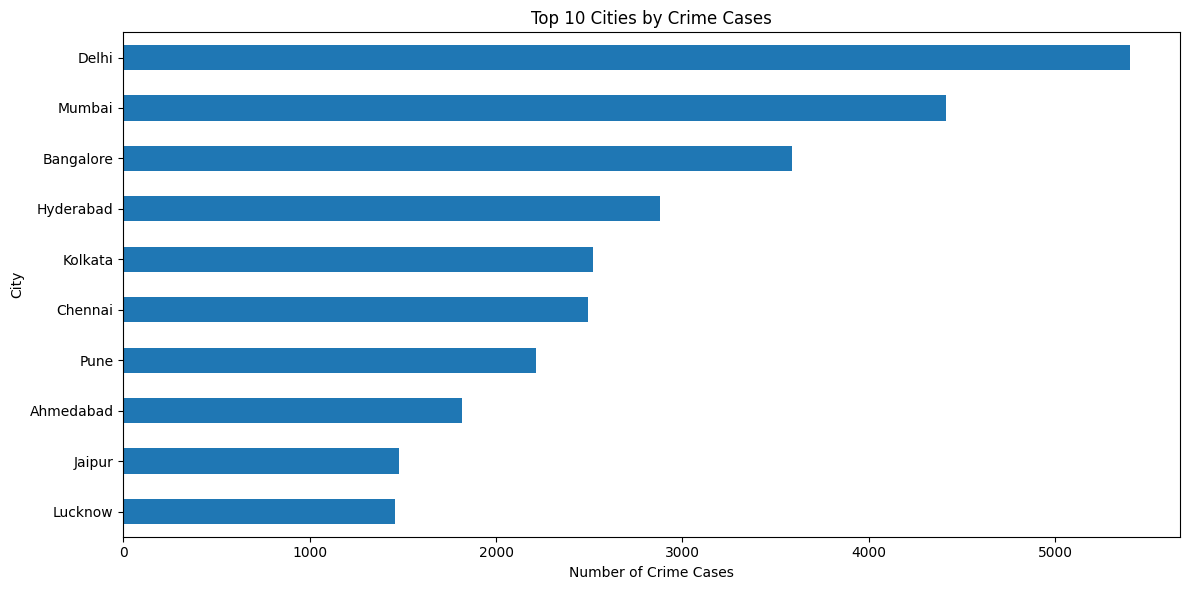

In [43]:
# Top 10 cities by number of crime cases

top_crime = (
    crime_df
    .groupby("City")
    .size()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 6))

top_crime.sort_values().plot(
    kind="barh"
)

plt.title("Top 10 Cities by Crime Cases")
plt.xlabel("Number of Crime Cases")
plt.ylabel("City")

plt.tight_layout()
plt.show()

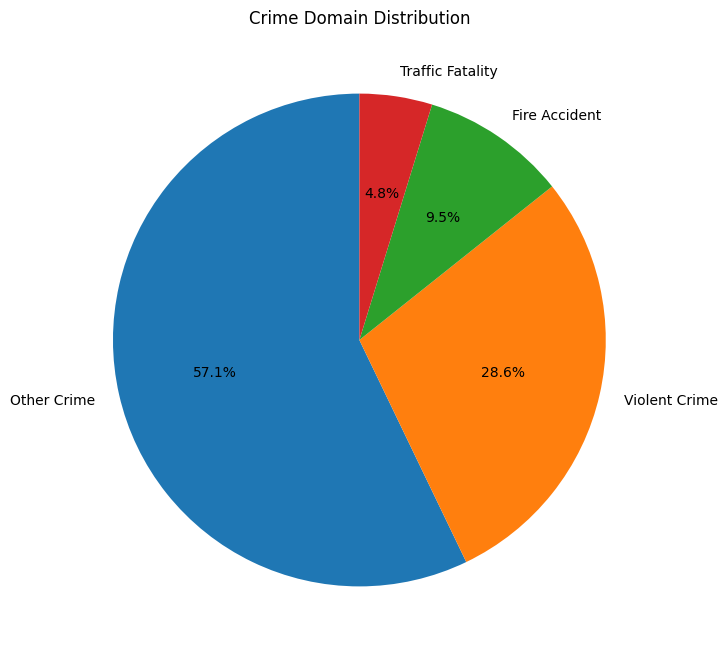

In [44]:
# Crime domain distribution

crime_domain = (
    crime_df["Crime Domain"]
    .value_counts()
)

plt.figure(figsize=(8, 8))

plt.pie(
    crime_domain.values,
    labels=crime_domain.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Crime Domain Distribution")

plt.show()


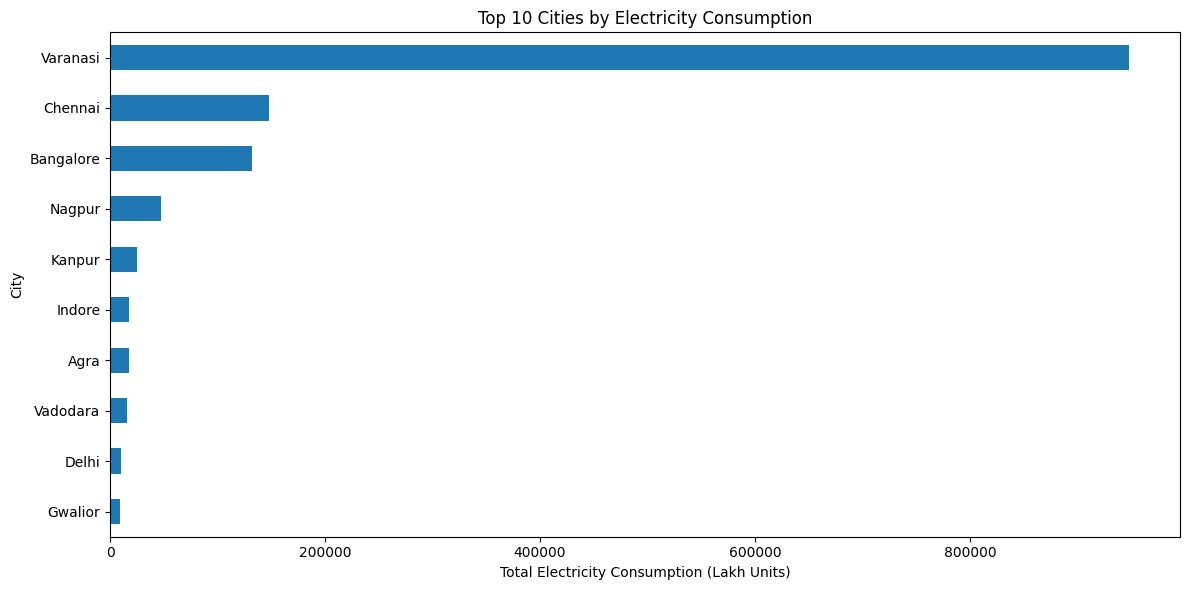

In [45]:
# Top cities by electricity consumption

top_electricity = (
    electricity_df
    .groupby("City")["total_consumption"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 6))

top_electricity.sort_values().plot(
    kind="barh"
)

plt.title("Top 10 Cities by Electricity Consumption")

plt.xlabel(
    "Total Electricity Consumption (Lakh Units)"
)

plt.ylabel("City")

plt.tight_layout()
plt.show()


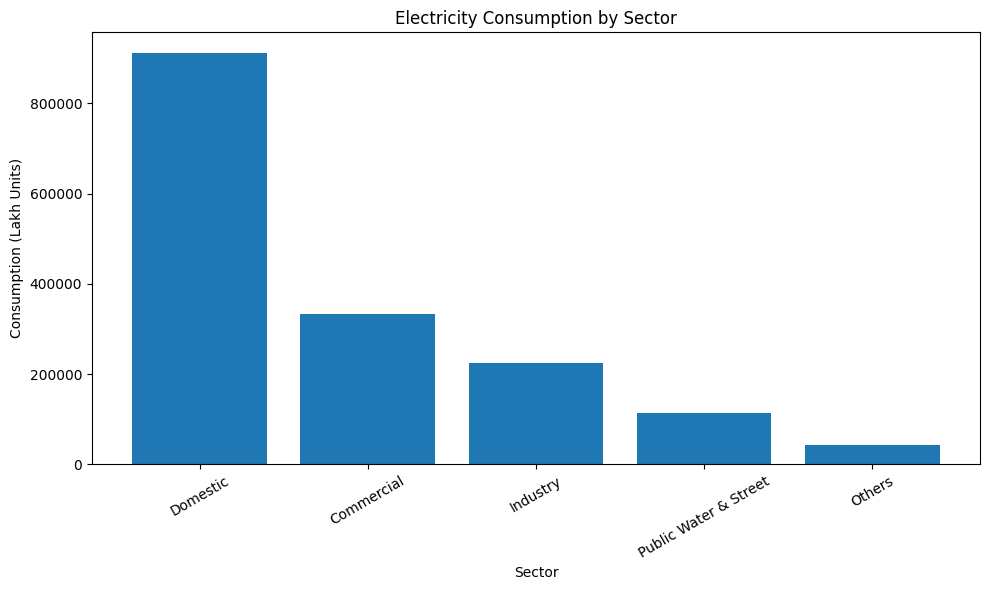

In [46]:
# Electricity consumption by purpose

sector_values = [
    electricity_df["domestic_consumption"].sum(),
    electricity_df["commercial_consumption"].sum(),
    electricity_df["industry_consumption"].sum(),
    electricity_df[
        "public_water_street_consumption"
    ].sum(),
    electricity_df["other_consumption"].sum()
]

sector_names = [
    "Domestic",
    "Commercial",
    "Industry",
    "Public Water & Street",
    "Others"
]

plt.figure(figsize=(10, 6))

plt.bar(
    sector_names,
    sector_values
)

plt.title(
    "Electricity Consumption by Sector"
)

plt.xlabel("Sector")

plt.ylabel(
    "Consumption (Lakh Units)"
)

plt.xticks(rotation=30)

plt.tight_layout()

plt.show()


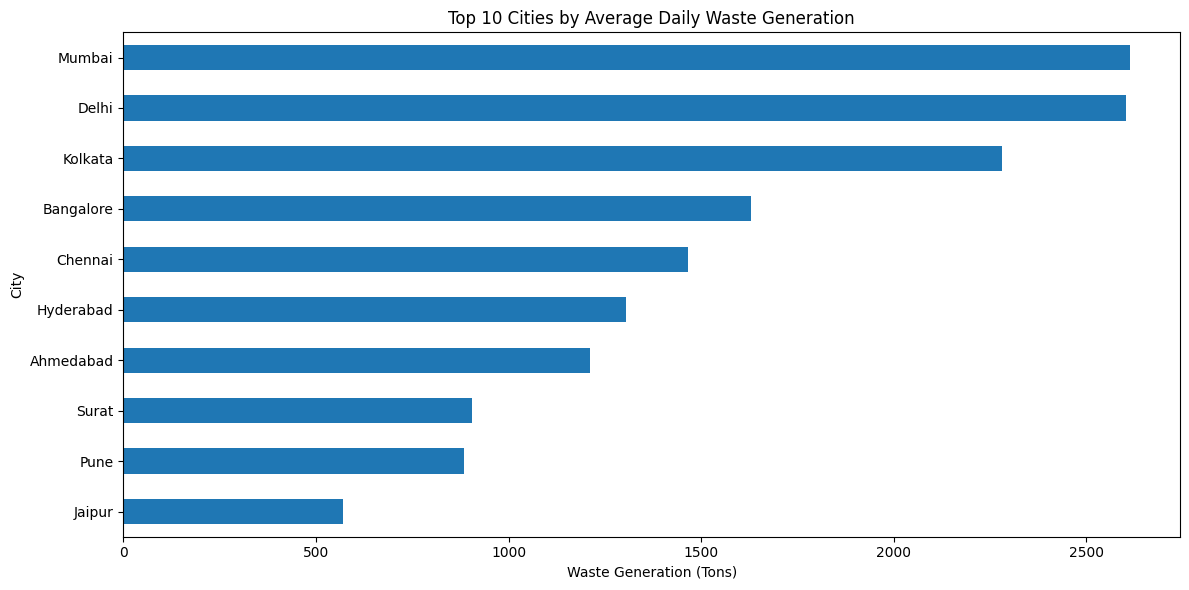

In [47]:
# Top 10 cities by average daily waste generation

top_waste = (
    waste_df
    .groupby("City")[
        "Daily_Waste_Generation_Tons"
    ]
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 6))

top_waste.sort_values().plot(
    kind="barh"
)

plt.title(
    "Top 10 Cities by Average Daily Waste Generation"
)

plt.xlabel("Waste Generation (Tons)")

plt.ylabel("City")

plt.tight_layout()

plt.show()


<Figure size 1200x600 with 0 Axes>

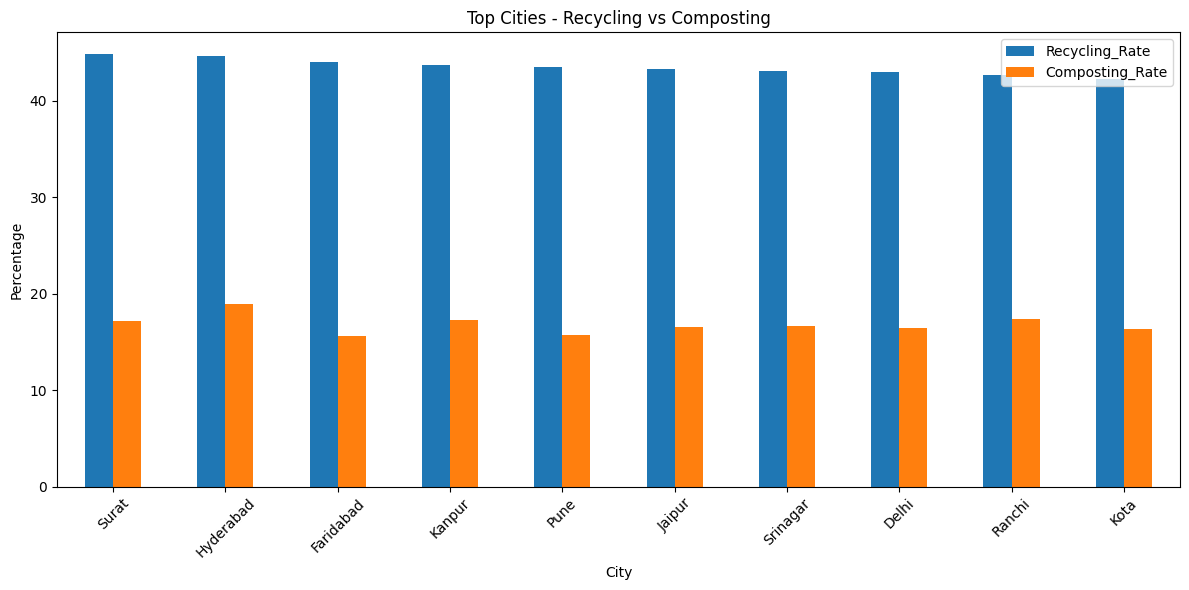

In [48]:
# Compare recycling and composting rates

waste_rates = (
    waste_df
    .groupby("City")
    [
        [
            "Recycling_Rate",
            "Composting_Rate"
        ]
    ]
    .mean()
    .sort_values(
        "Recycling_Rate",
        ascending=False
    )
    .head(10)
)

plt.figure(figsize=(12, 6))

waste_rates.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title(
    "Top Cities - Recycling vs Composting"
)

plt.xlabel("City")

plt.ylabel("Percentage")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()


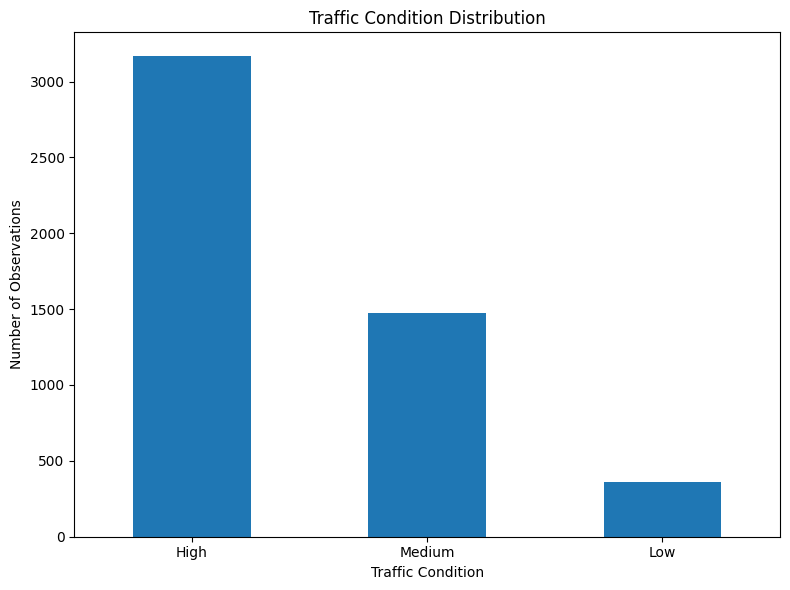

In [49]:
# Traffic condition distribution

traffic_condition = (
    mobility_df["Traffic_Condition"]
    .value_counts()
)

plt.figure(figsize=(8, 6))

traffic_condition.plot(
    kind="bar"
)

plt.title(
    "Traffic Condition Distribution"
)

plt.xlabel("Traffic Condition")

plt.ylabel("Number of Observations")

plt.xticks(rotation=0)

plt.tight_layout()

plt.show()


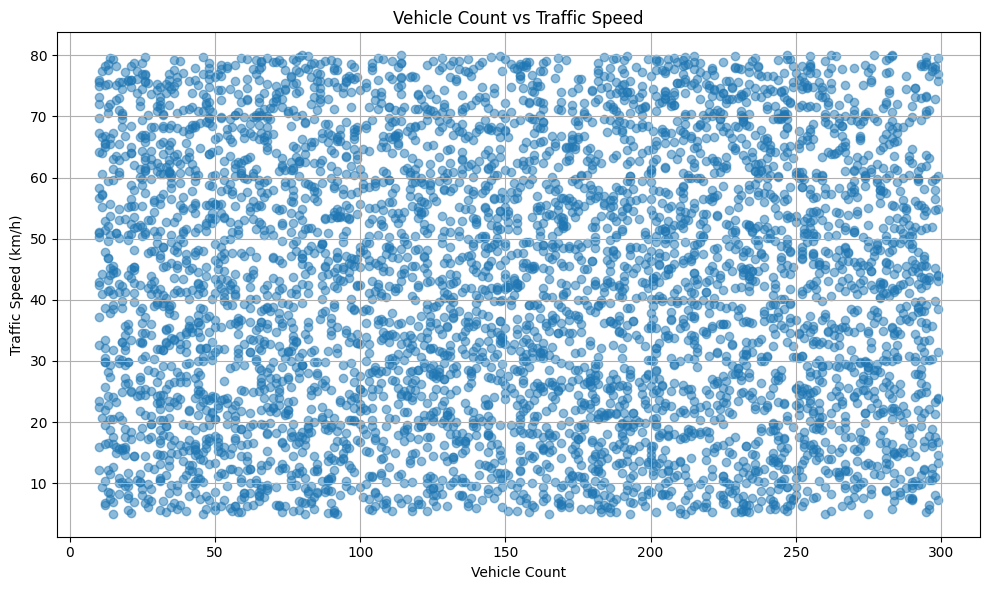

In [50]:
# Relationship between vehicles and traffic speed

plt.figure(figsize=(10, 6))

plt.scatter(
    mobility_df["Vehicle_Count"],
    mobility_df["Traffic_Speed_kmh"],
    alpha=0.5
)

plt.title(
    "Vehicle Count vs Traffic Speed"
)

plt.xlabel("Vehicle Count")

plt.ylabel("Traffic Speed (km/h)")

plt.grid(True)

plt.tight_layout()

plt.show()


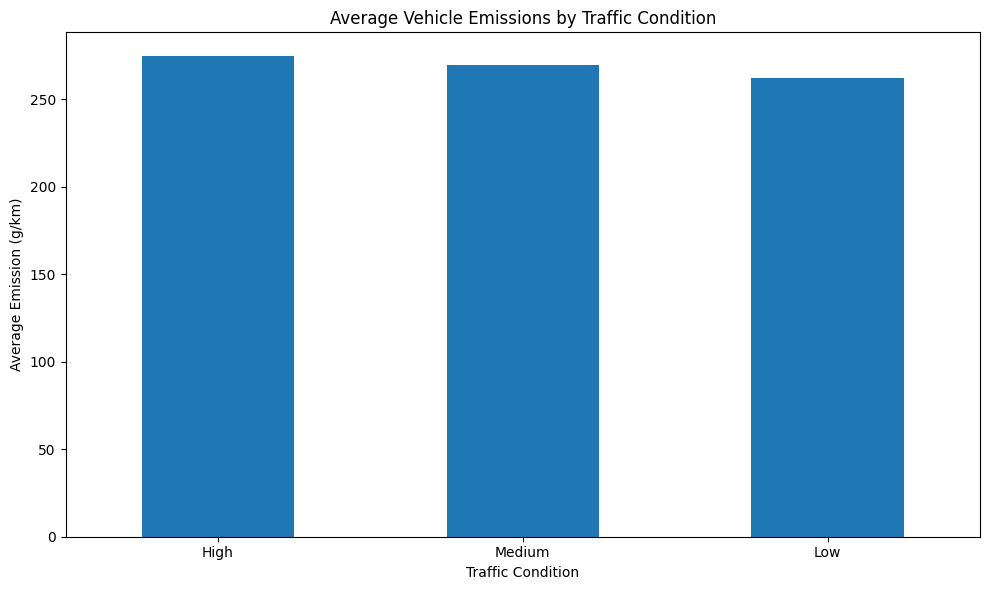

In [52]:
# Emission levels by traffic condition

emission_condition = (
    mobility_df
    .groupby("Traffic_Condition")[
        "Emission_Levels_g_km"
    ]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))

emission_condition.plot(
    kind="bar"
)

plt.title(
    "Average Vehicle Emissions by Traffic Condition"
)

plt.xlabel("Traffic Condition")

plt.ylabel("Average Emission (g/km)")

plt.xticks(rotation=0)

plt.tight_layout()

plt.show()


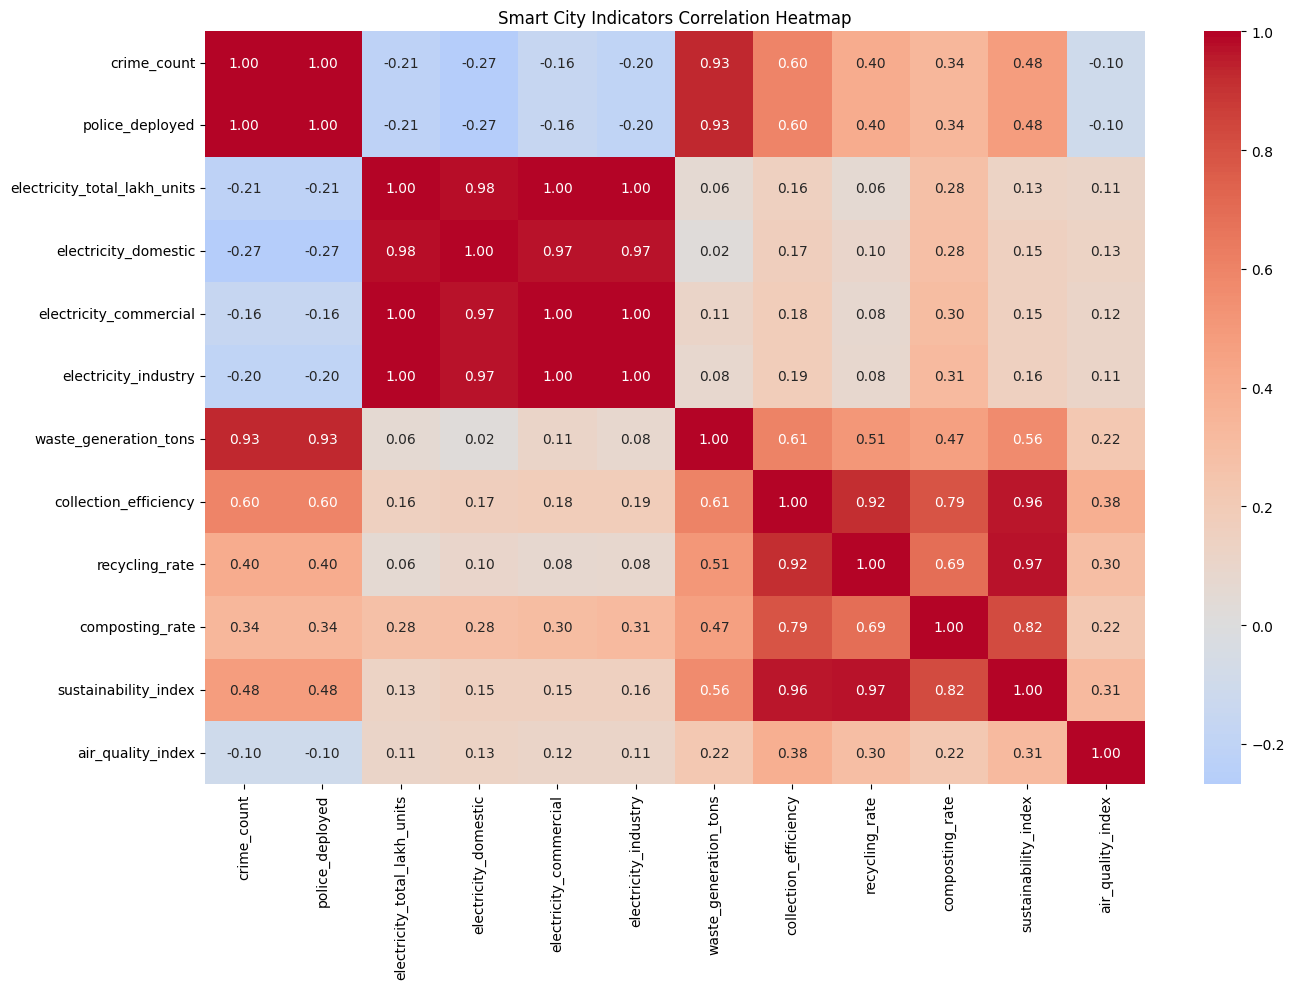

In [53]:
# Select important combined smart city indicators

heatmap_columns = [
    "crime_count",
    "police_deployed",
    "electricity_total_lakh_units",
    "electricity_domestic",
    "electricity_commercial",
    "electricity_industry",
    "waste_generation_tons",
    "collection_efficiency",
    "recycling_rate",
    "composting_rate",
    "sustainability_index",
    "air_quality_index"
]

correlation_matrix = (
    dashboard_df[heatmap_columns]
    .corr()
)

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title(
    "Smart City Indicators Correlation Heatmap"
)

plt.tight_layout()

plt.show()



In [54]:
# Select important cities

selected_cities = [
    "Agra",
    "Ahmedabad",
    "Bangalore",
    "Bhopal",
    "Chennai",
    "Delhi",
    "Hyderabad",
    "Indore",
    "Jaipur",
    "Lucknow",
    "Mumbai",
    "Pune"
]

city_comparison = dashboard_df[
    dashboard_df["city"].isin(
        selected_cities
    )
]

display(
    city_comparison[
        [
            "city",
            "crime_count",
            "electricity_total_lakh_units",
            "waste_generation_tons",
            "collection_efficiency",
            "recycling_rate",
            "sustainability_index"
        ]
    ]
)


,city,crime_count,electricity_total_lakh_units,waste_generation_tons,collection_efficiency,recycling_rate,sustainability_index
1,Agra,764.0,17191.0000,215.479263,68.570000,36.305263,46.225263
2,Ahmedabad,1817.0,NaN,1212.427872,78.001596,40.803723,54.799468
13,Bangalore,3588.0,131675.7668,1630.527337,80.607538,42.078894,57.502010
23,Bhopal,690.0,NaN,184.197705,66.506011,37.154645,45.444809
29,Chennai,2493.0,147338.0000,1465.891295,74.569430,39.680311,50.738342
35,Delhi,5400.0,10187.6700,2604.224798,79.720707,42.972222,56.070707
53,Hyderabad,2881.0,NaN,1303.803889,82.350505,44.701515,59.860101
55,Indore,699.0,17576.3700,184.146567,67.531841,36.523383,45.608955
58,Jaipur,1479.0,2873.5010,569.072151,79.826344,43.259677,56.746774
80,Lucknow,1456.0,NaN,422.922424,68.377778,39.046465,46.838889


,city,sustainability_index,recycling_rate,collection_efficiency,waste_generation_tons
53,Hyderabad,59.860101,44.701515,82.350505,1303.803889
129,Surat,58.595699,44.866129,81.365054,904.612796
13,Bangalore,57.502010,42.078894,80.607538,1630.527337
58,Jaipur,56.746774,43.259677,79.826344,569.072151
70,Kanpur,56.123037,43.718325,75.876963,365.952775
35,Delhi,56.070707,42.972222,79.720707,2604.224798
128,Srinagar,55.579082,43.150000,75.490306,329.888061
102,Prayagraj,55.300000,41.870313,75.621354,305.077604
39,Faridabad,54.855276,44.070352,74.366332,154.395477
2,Ahmedabad,54.799468,40.803723,78.001596,1212.427872


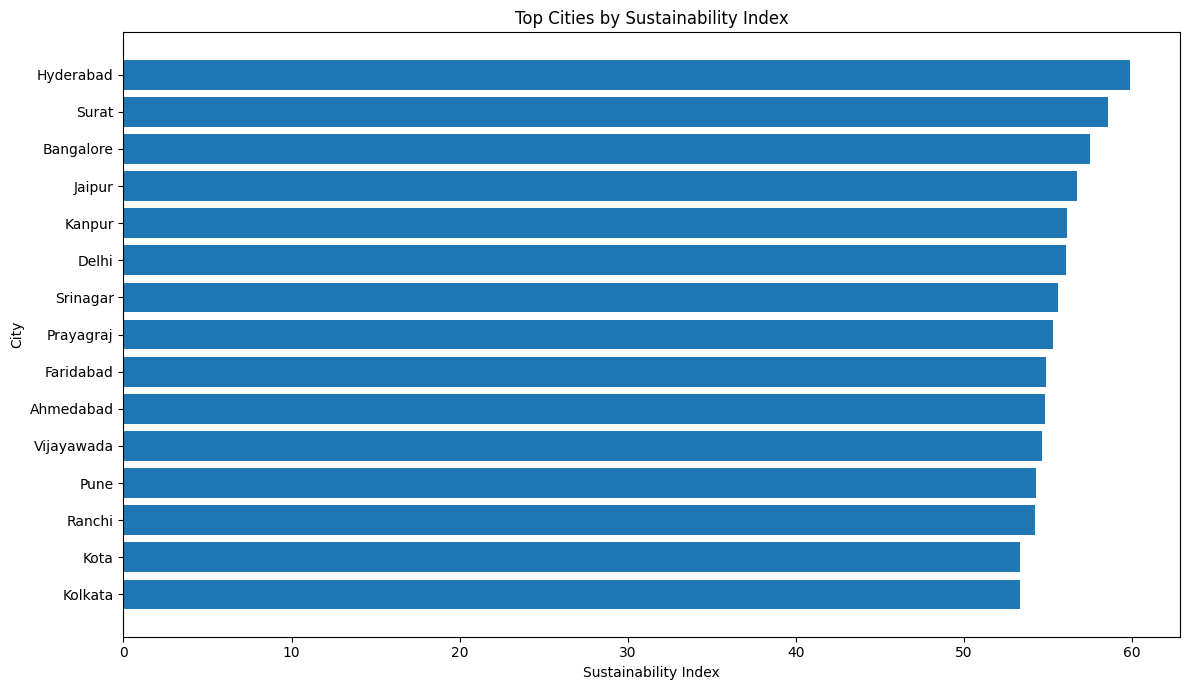

In [55]:
# Rank cities according to sustainability index

sustainability_ranking = (
    dashboard_df[
        [
            "city",
            "sustainability_index",
            "recycling_rate",
            "collection_efficiency",
            "waste_generation_tons"
        ]
    ]
    .dropna()
    .sort_values(
        "sustainability_index",
        ascending=False
    )
    .head(15)
)

display(sustainability_ranking)

plt.figure(figsize=(12, 7))

plt.barh(
    sustainability_ranking["city"],
    sustainability_ranking["sustainability_index"]
)

plt.title(
    "Top Cities by Sustainability Index"
)

plt.xlabel("Sustainability Index")

plt.ylabel("City")

plt.gca().invert_yaxis()

plt.tight_layout()

plt.show()



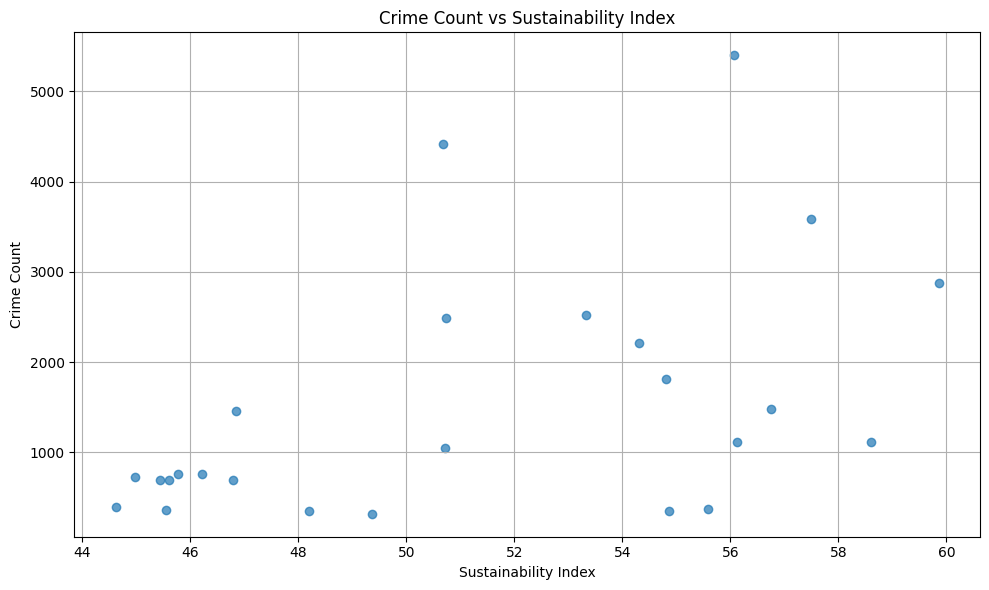

In [57]:
# Analyze relationship between crime and sustainability

analysis_df = dashboard_df.dropna(
    subset=[
        "crime_count",
        "sustainability_index"
    ]
)

plt.figure(figsize=(10, 6))

plt.scatter(
    analysis_df["sustainability_index"],
    analysis_df["crime_count"],
    alpha=0.7
)

plt.title(
    "Crime Count vs Sustainability Index"
)

plt.xlabel("Sustainability Index")

plt.ylabel("Crime Count")

plt.grid(True)

plt.tight_layout()

plt.show()


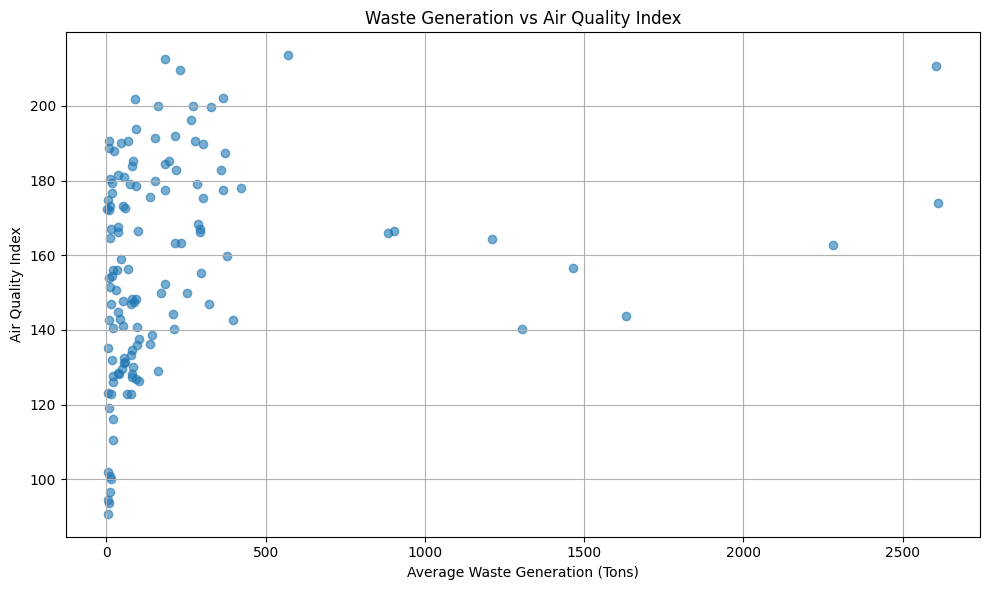

In [58]:
# Relationship between waste generation and air quality

analysis_df = dashboard_df.dropna(
    subset=[
        "waste_generation_tons",
        "air_quality_index"
    ]
)

plt.figure(figsize=(10, 6))

plt.scatter(
    analysis_df["waste_generation_tons"],
    analysis_df["air_quality_index"],
    alpha=0.6
)

plt.title(
    "Waste Generation vs Air Quality Index"
)

plt.xlabel(
    "Average Waste Generation (Tons)"
)

plt.ylabel(
    "Air Quality Index"
)

plt.grid(True)

plt.tight_layout()

plt.show()


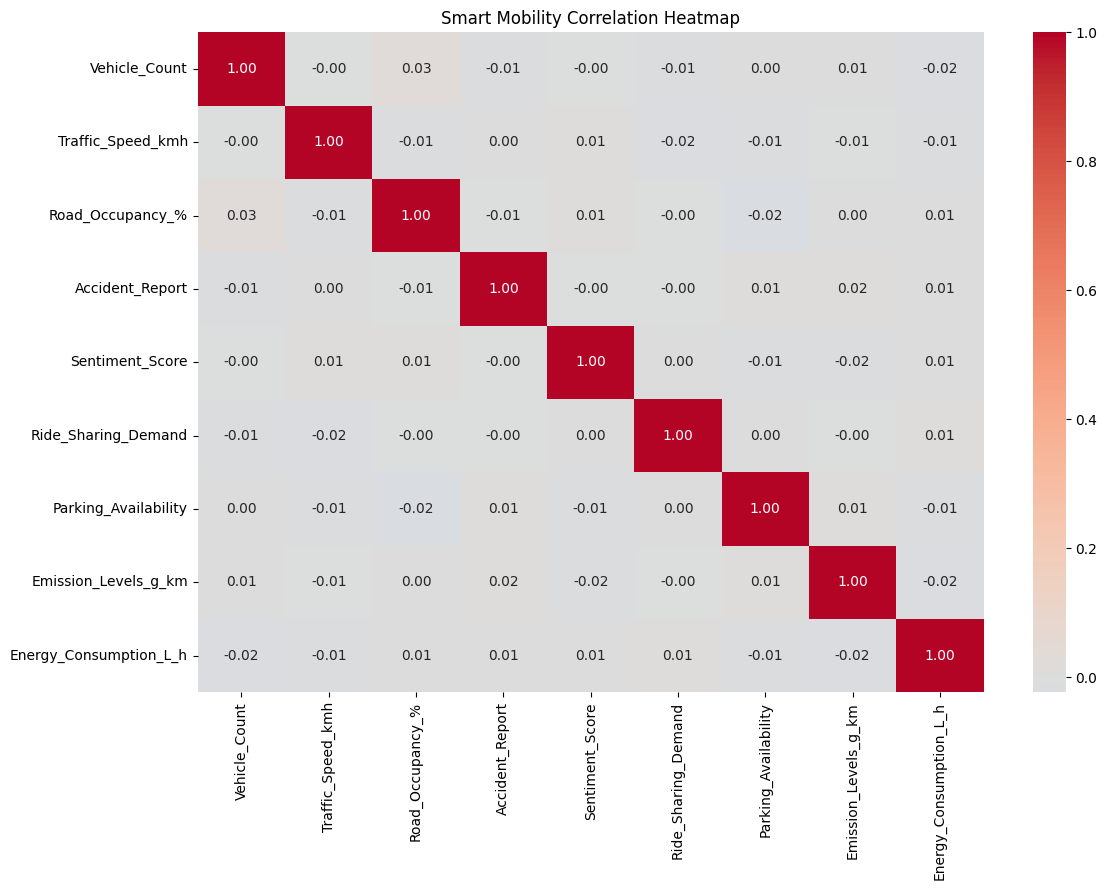

In [59]:
# Mobility dataset correlation heatmap

mobility_numeric = mobility_df[
    [
        "Vehicle_Count",
        "Traffic_Speed_kmh",
        "Road_Occupancy_%",
        "Accident_Report",
        "Sentiment_Score",
        "Ride_Sharing_Demand",
        "Parking_Availability",
        "Emission_Levels_g_km",
        "Energy_Consumption_L_h"
    ]
]

mobility_corr = mobility_numeric.corr()

plt.figure(figsize=(12, 9))

sns.heatmap(
    mobility_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title(
    "Smart Mobility Correlation Heatmap"
)

plt.tight_layout()

plt.show()


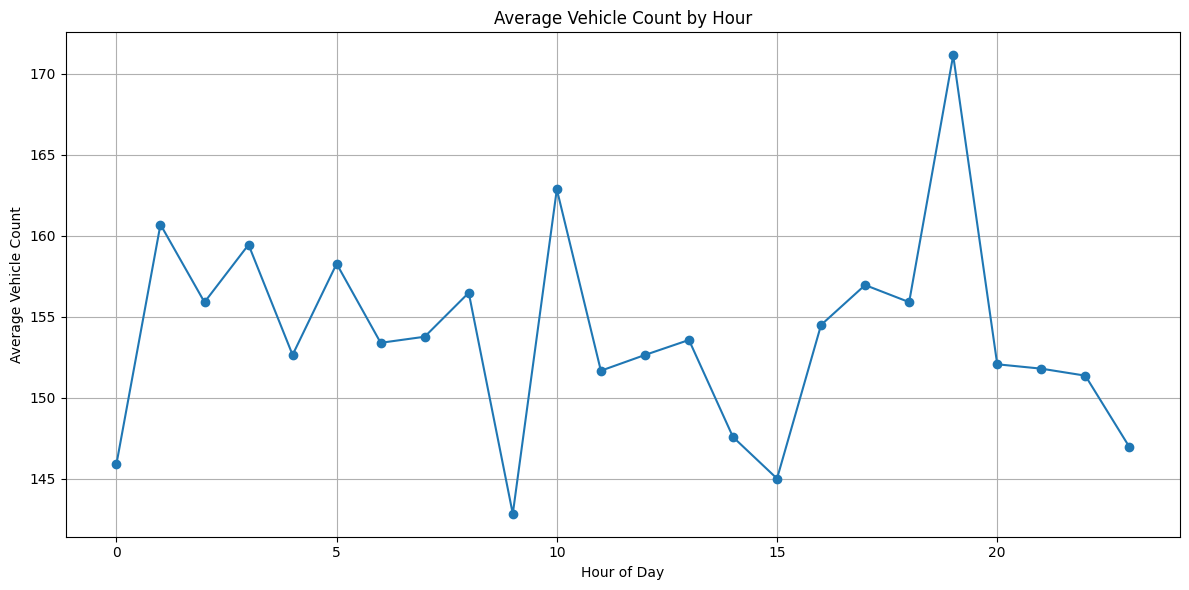

In [60]:
# Calculate hourly traffic statistics

mobility_time = mobility_df.copy()

mobility_time["Hour"] = (
    mobility_time["Timestamp"]
    .dt.hour
)

hourly_traffic = (
    mobility_time
    .groupby("Hour")
    [
        [
            "Vehicle_Count",
            "Traffic_Speed_kmh",
            "Road_Occupancy_%"
        ]
    ]
    .mean()
)

plt.figure(figsize=(12, 6))

plt.plot(
    hourly_traffic.index,
    hourly_traffic["Vehicle_Count"],
    marker="o"
)

plt.title(
    "Average Vehicle Count by Hour"
)

plt.xlabel("Hour of Day")

plt.ylabel("Average Vehicle Count")

plt.grid(True)

plt.tight_layout()

plt.show()


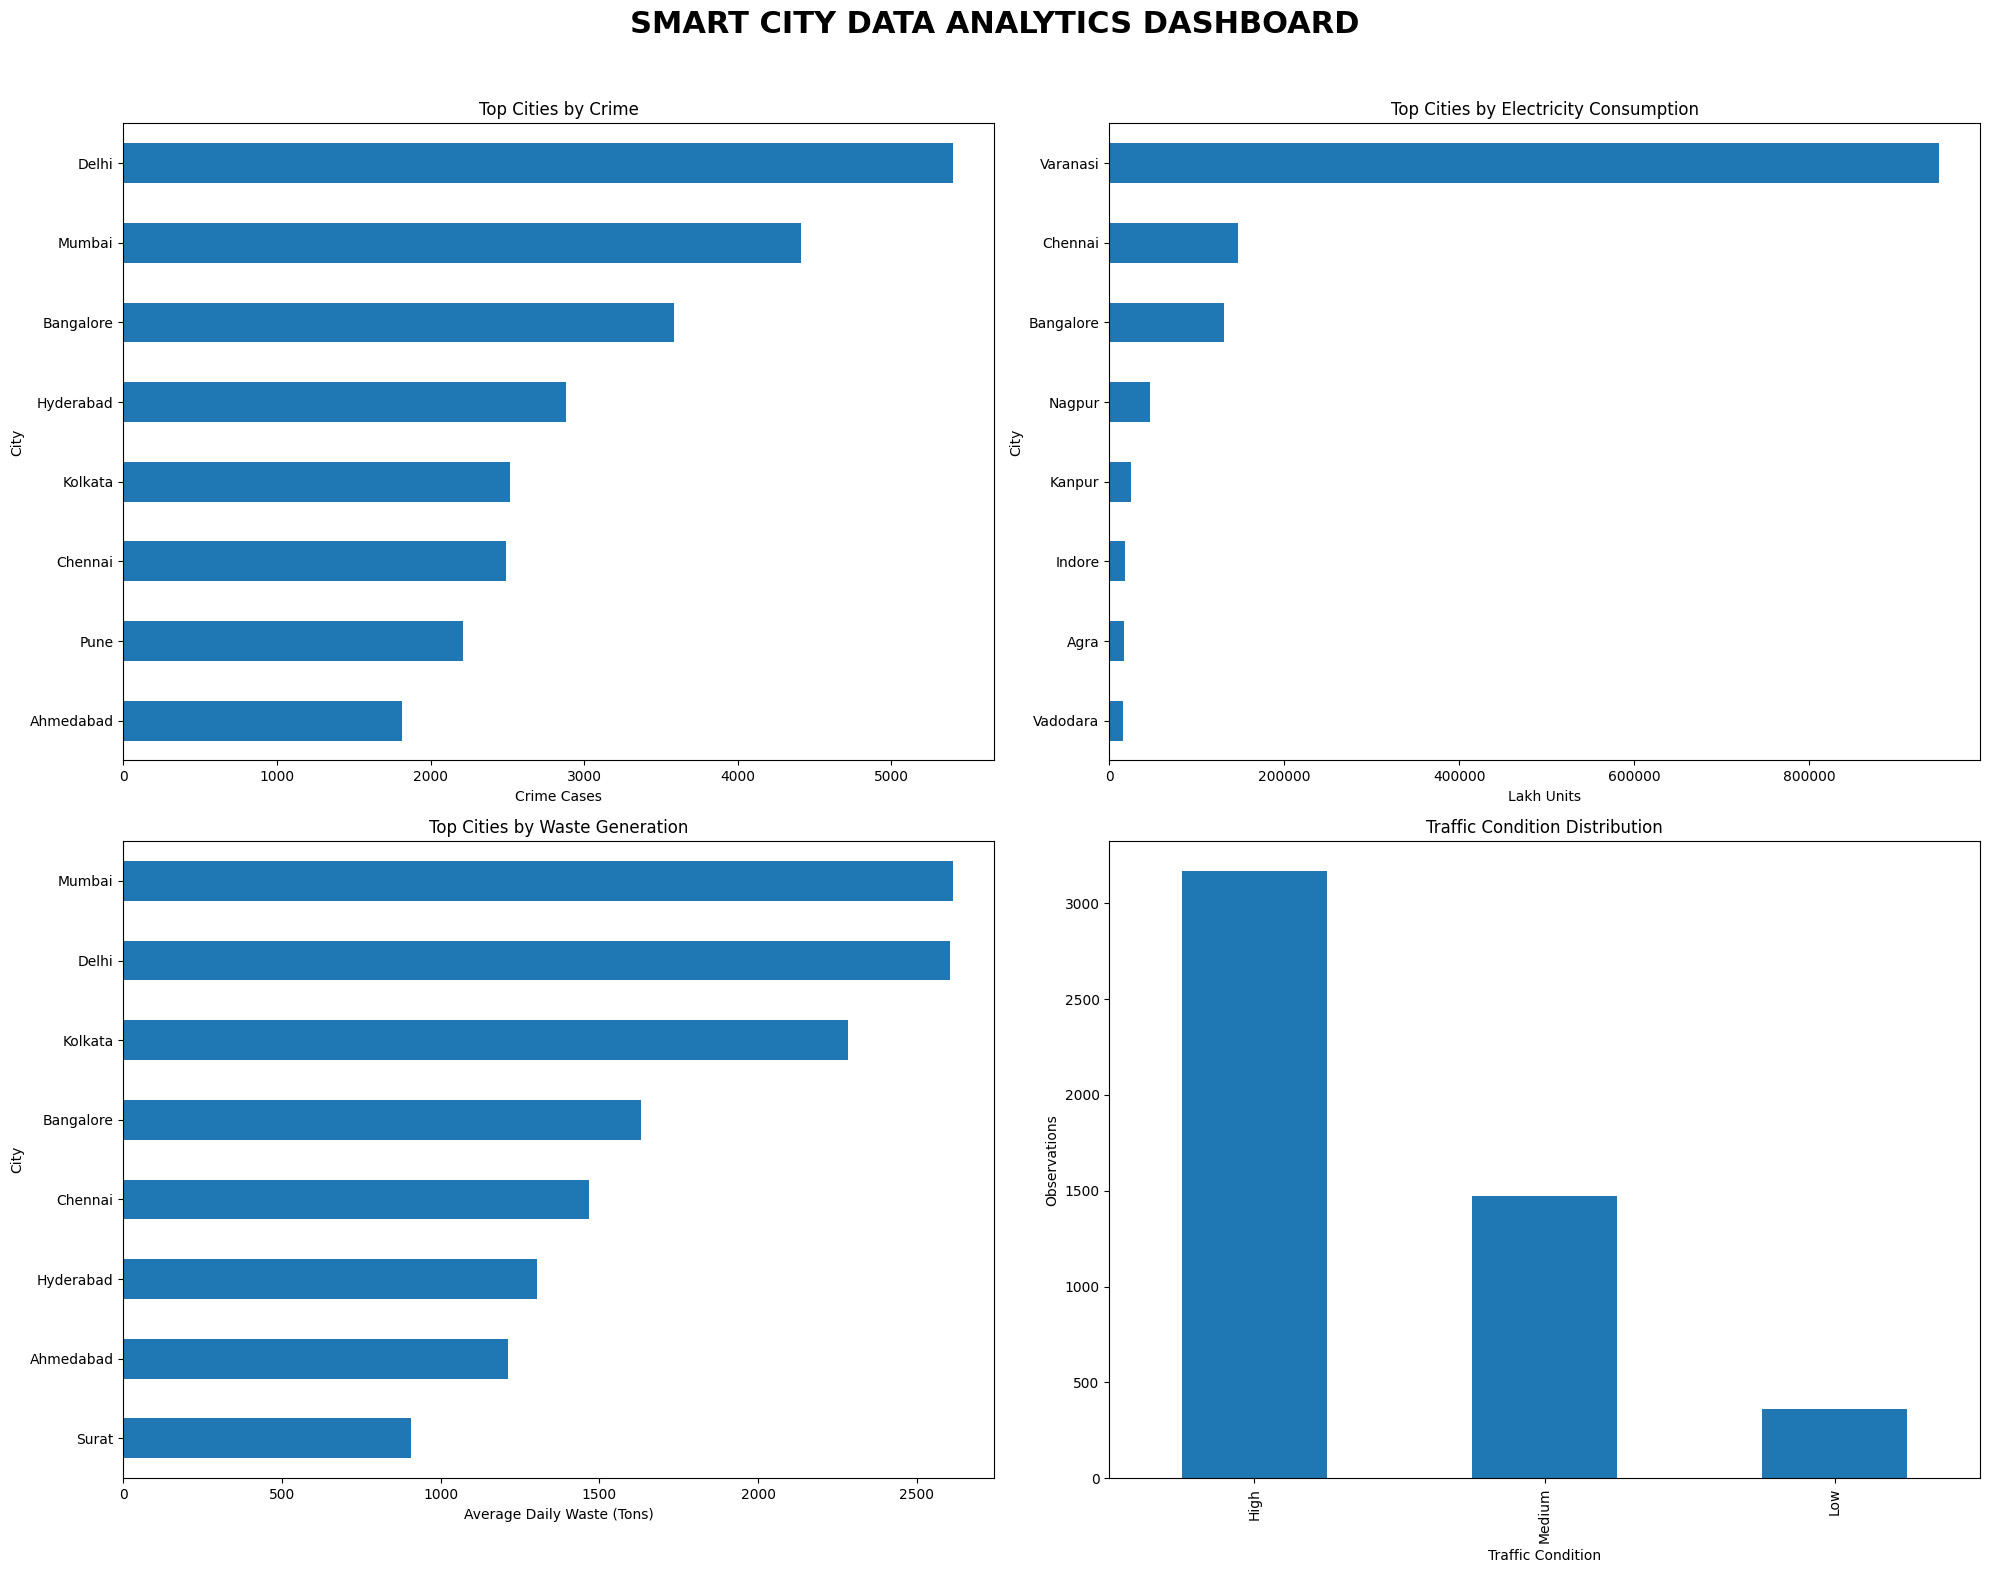

In [61]:
# ==========================================
# FINAL SMART CITY ANALYTICS DASHBOARD
# ==========================================

fig = plt.figure(figsize=(20, 16))

# ------------------------------------------
# 1. Crime
# ------------------------------------------

ax1 = plt.subplot(2, 2, 1)

top_crime = (
    crime_df
    .groupby("City")
    .size()
    .sort_values(ascending=False)
    .head(8)
)

top_crime.sort_values().plot(
    kind="barh",
    ax=ax1
)

ax1.set_title(
    "Top Cities by Crime"
)

ax1.set_xlabel(
    "Crime Cases"
)

# ------------------------------------------
# 2. Electricity
# ------------------------------------------

ax2 = plt.subplot(2, 2, 2)

top_electricity = (
    electricity_df
    .groupby("City")["total_consumption"]
    .sum()
    .sort_values(ascending=False)
    .head(8)
)

top_electricity.sort_values().plot(
    kind="barh",
    ax=ax2
)

ax2.set_title(
    "Top Cities by Electricity Consumption"
)

ax2.set_xlabel(
    "Lakh Units"
)

# ------------------------------------------
# 3. Waste
# ------------------------------------------

ax3 = plt.subplot(2, 2, 3)

top_waste = (
    waste_df
    .groupby("City")[
        "Daily_Waste_Generation_Tons"
    ]
    .mean()
    .sort_values(ascending=False)
    .head(8)
)

top_waste.sort_values().plot(
    kind="barh",
    ax=ax3
)

ax3.set_title(
    "Top Cities by Waste Generation"
)

ax3.set_xlabel(
    "Average Daily Waste (Tons)"
)

# ------------------------------------------
# 4. Mobility
# ------------------------------------------

ax4 = plt.subplot(2, 2, 4)

traffic = (
    mobility_df["Traffic_Condition"]
    .value_counts()
)

traffic.plot(
    kind="bar",
    ax=ax4
)

ax4.set_title(
    "Traffic Condition Distribution"
)

ax4.set_xlabel(
    "Traffic Condition"
)

ax4.set_ylabel(
    "Observations"
)

# ------------------------------------------

plt.suptitle(
    "SMART CITY DATA ANALYTICS DASHBOARD",
    fontsize=22,
    fontweight="bold"
)

plt.tight_layout(
    rect=[0, 0, 1, 0.96]
)

plt.show()



In [62]:
# Display final combined smart city information directly from MySQL

cursor.execute("""
SELECT
    city,
    crime_count,
    crime_closure_rate,
    electricity_total_lakh_units,
    waste_generation_tons,
    collection_efficiency,
    recycling_rate,
    sustainability_index,
    air_quality_index
FROM city_smart_dashboard
ORDER BY sustainability_index DESC
""")

final_rows = cursor.fetchall()

final_df = pd.DataFrame(
    final_rows,
    columns=[
        "City",
        "Crime Count",
        "Crime Closure Rate",
        "Electricity Consumption",
        "Waste Generation",
        "Collection Efficiency",
        "Recycling Rate",
        "Sustainability Index",
        "Air Quality Index"
    ]
)

display(final_df)



,City,Crime Count,Crime Closure Rate,Electricity Consumption,Waste Generation,Collection Efficiency,Recycling Rate,Sustainability Index,Air Quality Index
0,Hyderabad,2881.0,0.506421,NaN,1303.803889,82.350505,44.701515,59.860101,140.282828
1,Surat,1111.0,0.511251,NaN,904.612796,81.365054,44.866129,58.595699,166.553763
2,Bangalore,3588.0,0.490245,131675.76680,1630.527337,80.607538,42.078894,57.502010,143.648241
3,Jaipur,1479.0,0.510480,2873.50100,569.072151,79.826344,43.259677,56.746774,213.526882
4,Kanpur,1112.0,0.513489,24563.50000,365.952775,75.876963,43.718325,56.123037,177.539267
...,...,...,...,...,...,...,...,...,...
141,Solapur Smart City,NaN,NaN,2825.55137,NaN,NaN,NaN,NaN,NaN
142,Thane,706.0,0.536827,NaN,NaN,NaN,NaN,NaN,NaN
143,Thoothukudi,NaN,NaN,3199.04400,NaN,NaN,NaN,NaN,NaN
144,Tirupati,NaN,NaN,131.63000,NaN,NaN,NaN,NaN,NaN


In [63]:
# Close MySQL connection

cursor.close()

connection.close()

print("MySQL connection closed successfully")



MySQL connection closed successfully
